In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import pickle
import math
import cv2

from notebooks.imports import *
from src.utils import pmf_utils

### Config

In [3]:
from config import dir_config

raw_dir = Path(dir_config.data.raw)
processed_dir = Path(dir_config.data.processed)

### Load and Preprocess data

In [4]:
with open(processed_dir / "motion_data_compiled.pkl", "rb") as f:
    motion_data_dict = pickle.load(f)

data = pd.read_csv(Path(processed_dir, "valid_data.csv"), index_col=None)
data

,agg_index,idx_session,data_source,subject_id,session_id,idx_valid_trial,idx_correction,is_correction_trial,signed_coherence,target,choice,reaction_time,outcome,reward_amount,fixation_duration,stimulus_duration,reinforcement_duration,intertrial_delay,is_pulse_trial,pulse_onset,pulse_duration,pulse_coherence,stimulus_seed,pulse_type
0,0,0,uw,DBM11,10_1,1,0,False,100,1,1,1.080817,1.0,1.5,0.530901,25.0,0.0,0.500000,True,0.416750,0.066680,-100,612658,-3.0
1,1,0,uw,DBM11,10_1,2,0,False,100,1,0,0.469520,0.0,NaN,0.577326,25.0,0.0,13.689771,False,0.416750,0.066680,100,463182,0.0
2,2,0,uw,DBM11,10_1,3,0,False,-100,-1,0,2.171707,1.0,1.5,0.556890,25.0,0.0,0.500000,True,0.416750,0.066680,100,165712,3.0
3,3,0,uw,DBM11,10_1,4,0,False,-100,-1,0,0.476003,1.0,1.5,0.548262,25.0,0.0,0.500000,False,0.050010,0.066680,-100,418800,-0.0
4,4,0,uw,DBM11,10_1,5,0,False,-100,-1,0,0.971870,1.0,1.5,0.561377,25.0,0.0,0.500000,False,0.233380,0.066680,-100,372882,-0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113869,113869,297,ucla,PSUIM9,9_1,346,0,False,18,1,1,1.108688,1.0,2.6,1.000000,60.0,0.5,0.250000,True,0.029568,0.050560,100,346,1.0
113870,113870,297,ucla,PSUIM9,9_1,347,0,False,36,1,1,1.598707,1.0,2.6,1.000000,60.0,0.5,0.250000,False,NaN,NaN,0,347,0.0
113871,113871,297,ucla,PSUIM9,9_1,348,0,False,-9,-1,1,2.292042,0.0,0.0,1.000000,60.0,1.5,0.252608,False,NaN,NaN,0,348,0.0
113872,113872,297,ucla,PSUIM9,9_1,349,0,False,36,1,1,1.706793,1.0,2.6,1.000000,60.0,0.5,0.250000,True,0.240538,0.050291,100,349,2.0


In [5]:
missing_in_motion_data = set(data.agg_index) - set(motion_data_dict)
extra_in_motion_data = set(motion_data_dict) - set(data.agg_index)

assert len(missing_in_motion_data) == 0, f"Missing keys in motion_data_dict: {missing_in_motion_data}"
assert len(extra_in_motion_data) == 0, f"Extra keys in motion_data_dict: {extra_in_motion_data}"


### Utils

In [23]:
# Define mapping from pulse_type to descriptive variable names
pulse_mapping = {
    -3: "late_left_pulse",
    -2: "middle_left_pulse",
    -1: "early_left_pulse",
    0: "control",
    1: "early_right_pulse",
    2: "middle_right_pulse",
    3: "late_right_pulse",
    }


In [ ]:
# Define mapping from pulse_type to descriptive variable names
def get_motion_data(trial_indices, motion_data_dict, motion_window = 'global'):
	# List to store the motion data
	motion_data_array = []

	# Keep track of the max shape of the motion data
	max_shape = (0, 0, 0)  # Initialize with zeros, assuming 3 dimensions (for safety)

	for i in trial_indices:
		try:
			if i in motion_data_dict:
				motion_data = np.array(motion_data_dict[i][motion_window].cpu().numpy())
				max_shape = tuple(map(max, zip(max_shape, motion_data.shape)))
				motion_data_array.append(motion_data)
			else:
				print(f"Warning: Index {i} not found in motion_data_dict.")
		except Exception as e:
			print(f"Error processing index {i}: {e}")

	padded_motion_data = []
	for data in motion_data_array:
		if data.ndim == 1:
			padded_data = np.pad(data, (0, max_shape[0] - data.shape[0]), mode="constant")
		elif data.ndim == 2:
			padded_data = np.pad(data, [(0, max_shape[0] - data.shape[0]), (0, max_shape[1] - data.shape[1])], mode="constant")
		elif data.ndim == 3:
			padded_data = np.pad(data, [(0, max_shape[0] - data.shape[0]), (0, max_shape[1] - data.shape[1]), (0, max_shape[2] - data.shape[2])], mode="constant")
		else:
			raise ValueError(f"Unexpected number of dimensions in motion data: {data.ndim}")
		padded_motion_data.append(padded_data)

	motion_data_array = np.array(padded_motion_data)
	return motion_data_array


### Code

In [24]:
pulse_type = data.pulse_type.unique()

for pt in sorted(pulse_type):
	print(f"{pt}: {pulse_mapping.get(pt, None)}")

-3.0: late_left_pulse
-2.0: middle_left_pulse
-1.0: early_left_pulse
0.0: control
1.0: early_right_pulse
2.0: middle_right_pulse
3.0: late_right_pulse


In [25]:
# note indices for each pulse_type and each signed_coherence under each pulse_type
indices = {}
for pt in pulse_type:
	indices[pt] = {}
	for sc in data.signed_coherence.unique():
		indices[pt][sc] = data[(data.pulse_type == pt) & (data.signed_coherence == sc)].index.tolist()


In [26]:

# Maximum length you want for all motion arrays (e.g., 600)
max_length = 600

# Function to pad arrays to max_length
def pad_to_max_length(arr, max_len):
    # Pad array to match max_len with NaN padding
    if len(arr) < max_len:
        return np.pad(arr, (0, max_len - len(arr)), mode='constant', constant_values=np.nan)
    return arr

# Initialize pulse_energy dictionary as {pulse_time: {coh: motion_array}}
pulse_energy = {}

# Loop through each pulse type and its corresponding coherences
for pt in pulse_type:
    pulse_time = pulse_mapping.get(pt, None)
    if pulse_time is None:
        print(f"⚠️ Unknown pulse_type {pt}, skipping.")
        continue

    pulse_energy[pulse_time] = {}

    for coh in indices.get(pt, {}):
        motion_energy = get_motion_data(indices[pt][coh], motion_data_dict)

        if motion_energy.size > 0:
            # Pad the motion energy to the desired length (600)
            padded_motion_energy = pad_to_max_length(motion_energy, max_length)
            pulse_energy[pulse_time][coh] = padded_motion_energy
        else:
            print(f"⚠️ Skipping pulse_time {pulse_time}, coherence {coh}: No valid data found")

# # # Optionally: Print the structure to verify
# for pulse_time, coherence_data in pulse_energy.items():
#     print(f"Pulse Time: {pulse_time}")
#     for coh, motion_data in coherence_data.items():
#         print(f"  Coherence {coh}: Data shape {motion_data.shape}")

# # Example of how to access the data:
# # To access the motion data for "early_left_pulse" at coherence 1
# early_left_pulse_coh1_data = pulse_energy.get("early_left_pulse", {}).get(1, np.full((max_length,), np.nan))

# # Print the length of a specific pulse data to verify
# print(f"Early left pulse coherence 1 data length: {len(early_left_pulse_coh1_data)}")


⚠️ Skipping pulse_time late_left_pulse, coherence -100: No valid data found
⚠️ Skipping pulse_time late_right_pulse, coherence 100: No valid data found


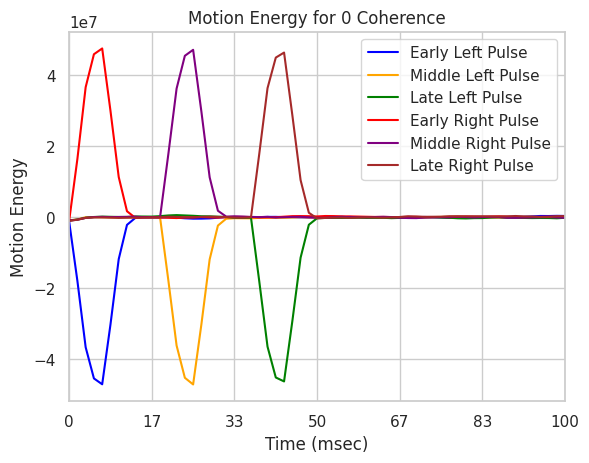

In [27]:
plt.plot(pulse_energy['early_left_pulse'][coh].mean(axis=0), label='Early Left Pulse', color='blue')
plt.plot(pulse_energy['middle_left_pulse'][coh].mean(axis=0), label='Middle Left Pulse', color='orange')
plt.plot(pulse_energy['late_left_pulse'][coh].mean(axis=0), label='Late Left Pulse', color='green')
plt.plot(pulse_energy['early_right_pulse'][coh].mean(axis=0), label='Early Right Pulse', color='red')
plt.plot(pulse_energy['middle_right_pulse'][coh].mean(axis=0), label='Middle Right Pulse', color='purple')
plt.plot(pulse_energy['late_right_pulse'][coh].mean(axis=0), label='Late Right Pulse', color='brown')
plt.title(f'Motion Energy for {coh} Coherence')

plt.legend()
plt.xlim([0, 60])
xticks = np.arange(0, 61, 10)
xticks_msec = np.round(xticks / 60, 2)*100

plt.xticks(xticks, xticks_msec.astype(int))
plt.xlabel('Time (msec)')
plt.ylabel('Motion Energy')
plt.show()

---
---